In [1]:
from google.colab import auth
from google.cloud import bigquery
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
import itertools

auth.authenticate_user()
client = bigquery.Client(project="data-analytics-mate")

query = """
WITH ses_params AS (
  SELECT
    ses.date AS session_date,
    ses.ga_session_id AS session_id,
    sp.continent AS continent,
    sp.country AS country,
    sp.device AS device,
    sp.browser AS browser,
    sp.mobile_model_name AS mobile_model,
    sp.operating_system AS operating_system,
    sp.language AS browser_language,
    sp.name AS traffic,
    sp.channel AS traffic_channel
  FROM `DA.session` ses
  LEFT JOIN `DA.session_params` sp
    ON ses.ga_session_id = sp.ga_session_id
),

acc_params AS (
  SELECT
    acs.ga_session_id AS session_id,
    acs.account_id AS account_id,
    acc.is_verified AS verified,
    acc.is_unsubscribed AS unsubscribed
  FROM `DA.account_session` acs
  INNER JOIN `DA.account` acc
    ON acs.account_id = acc.id
),

products AS (
  SELECT
    ord.ga_session_id AS session_id,
    prd.category AS product_category,
    prd.name AS product_name,
    prd.price AS product_price,
    prd.short_description AS product_description
  FROM `DA.order` ord
  INNER JOIN `DA.product` prd
    ON ord.item_id = prd.item_id
)

SELECT
  sp.session_date,
  sp.session_id,
  sp.continent,
  sp.country,
  sp.device,
  sp.browser,
  sp.mobile_model,
  sp.operating_system,
  sp.browser_language,
  sp.traffic,
  sp.traffic_channel,
  ap.account_id,
  ap.verified,
  ap.unsubscribed,
  pr.product_category,
  pr.product_name,
  pr.product_price,
  pr.product_description
FROM ses_params sp
LEFT JOIN acc_params ap
  ON sp.session_id = ap.session_id
LEFT JOIN products pr
  ON sp.session_id = pr.session_id """

df = client.query(query).to_dataframe(create_bqstorage_client=False)
df.head()

,session_date,session_id,continent,country,device,browser,mobile_model,operating_system,browser_language,traffic,traffic_channel,account_id,verified,unsubscribed,product_category,product_name,product_price,product_description
0,2020-11-01,5760483956,Americas,United States,desktop,Chrome,Safari,Macintosh,zh,<Other>,Paid Search,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,7115337200,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en-us,(organic),Organic Search,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3978035233,Europe,Norway,mobile,Chrome,<Other>,Web,zh,(direct),Direct,<NA>,<NA>,<NA>,Tables & desks,RÅSKOG,189.0,"Trolley, 35x45x78 cm"
3,2020-11-01,9648986282,Africa,Nigeria,mobile,Chrome,<Other>,Android,es-es,(direct),Direct,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,2020-11-01,4393441533,Asia,China,desktop,Chrome,Chrome,Windows,en-us,(direct),Direct,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"


In [2]:
df['session_date'] = pd.to_datetime(df['session_date'])
df.info()

print('Total columns:', df.shape[1])
print('Unique sessions:', df['session_id'].nunique())
print('Period: from', df['session_date'].min(), 'to', df['session_date'].max())

df.isna().sum()                    # number of nulls per column
df.isna().sum() / len(df) * 100    # share of nulls in %

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   session_date         349545 non-null  datetime64[ns]
 1   session_id           349545 non-null  Int64         
 2   continent            349545 non-null  object        
 3   country              349545 non-null  object        
 4   device               349545 non-null  object        
 5   browser              349545 non-null  object        
 6   mobile_model         349545 non-null  object        
 7   operating_system     349545 non-null  object        
 8   browser_language     235279 non-null  object        
 9   traffic              349545 non-null  object        
 10  traffic_channel      349545 non-null  object        
 11  account_id           27945 non-null   Int64         
 12  verified             27945 non-null   Int64         
 13  unsubscribed  

,0
session_date,0.000000
session_id,0.000000
continent,0.000000
country,0.000000
device,0.000000
browser,0.000000
mobile_model,0.000000
operating_system,0.000000
browser_language,32.689925
traffic,0.000000


**1. Total number of columns**

The dataset contains 18 columns and 349,545 rows.

**2. Numeric columns**

5 columns by data type: session_id, account_id, verified, unsubscribed, product_price.
In practice, product_price is the only real numeric metric. session_id and account_id are identifiers,
and verified and unsubscribed are binary flags (0/1), so they are essentially categorical.

**3. Categorical columns**

12 columns: continent, country, device, browser, mobile_model, operating_system,
browser_language, traffic, traffic_channel, product_category, product_name, product_description.

**4. Datetime columns**

1 column: session_date.

**5. Number of unique sessions**

349,545 unique sessions, the same as the number of rows. This means each session contains
at most one order, and joining the tables did not duplicate rows.

**6. Time period**

The data covers three months: from November 1, 2020 to January 31, 2021.



Top-3 continents by sales:
continent
Americas    17665280.0
Asia         7601298.3
Europe       5934624.2
Name: product_price, dtype: float64

Top-3 continents by orders:
continent
Americas    18553
Asia         7950
Europe       6261
Name: product_price, dtype: int64

Top-5 countries by sales:
country
United States     13943553.9
India              2809762.0
Canada             2437921.0
United Kingdom      938317.9
France              710692.8
Name: product_price, dtype: float64

Top-5 countries by orders:
country
United States     14673
India              3029
Canada             2560
United Kingdom     1029
France              678
Name: product_price, dtype: int64


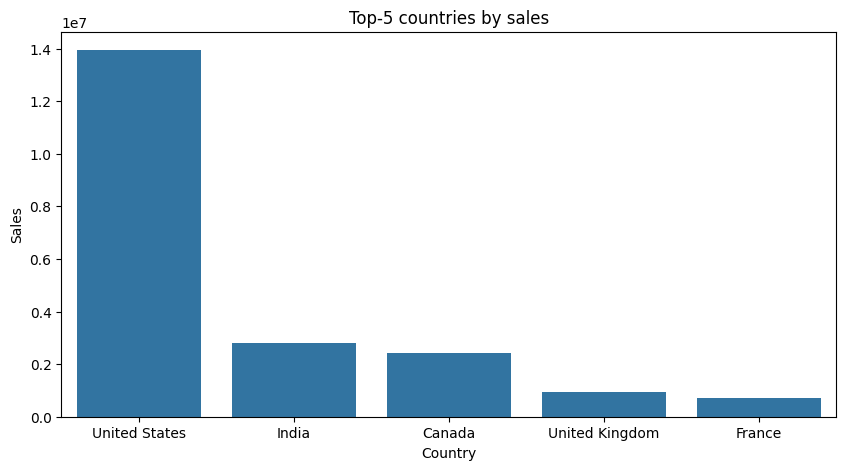


Top-10 categories by sales:
product_category
Sofas & armchairs                   8388254.5
Chairs                              6147748.8
Beds                                4919725.0
Bookcases & shelving units          3640818.1
Cabinets & cupboards                2336499.5
Outdoor furniture                   2142222.2
Tables & desks                      1790307.5
Chests of drawers & drawer units     906562.5
Bar furniture                        735503.0
Children's furniture                 467697.0
Name: product_price, dtype: float64

Top-10 categories by orders:
product_category
Bookcases & shelving units          7630
Chairs                              5952
Sofas & armchairs                   4301
Tables & desks                      2941
Beds                                2926
Cabinets & cupboards                2318
Outdoor furniture                   2229
Children's furniture                1702
Chests of drawers & drawer units    1452
Bar furniture                       1092
N

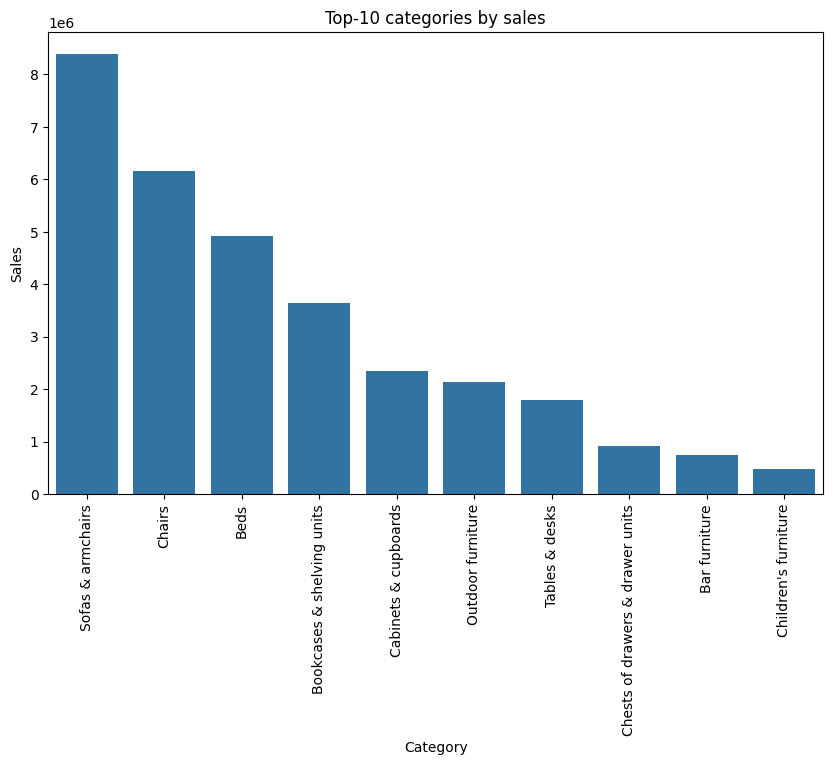


Top country by sales is United States

Top-10 categories: overall vs top country (% of revenue):


,"Overall, % of sales","United States, % of sales","Difference, p.p.",Rank overall,Rank United States
product_category,,,,,
Sofas & armchairs,26.24,26.59,0.35,1,1
Chairs,19.23,18.79,-0.44,2,2
Beds,15.39,15.87,0.48,3,3
Bookcases & shelving units,11.39,11.24,-0.15,4,4
Cabinets & cupboards,7.31,7.13,-0.18,5,5
Outdoor furniture,6.70,6.66,-0.04,6,6
Tables & desks,5.60,5.58,-0.02,7,7
Chests of drawers & drawer units,2.84,2.74,-0.09,8,8
Bar furniture,2.30,2.37,0.07,9,9


Categories in both top-10 lists: 10


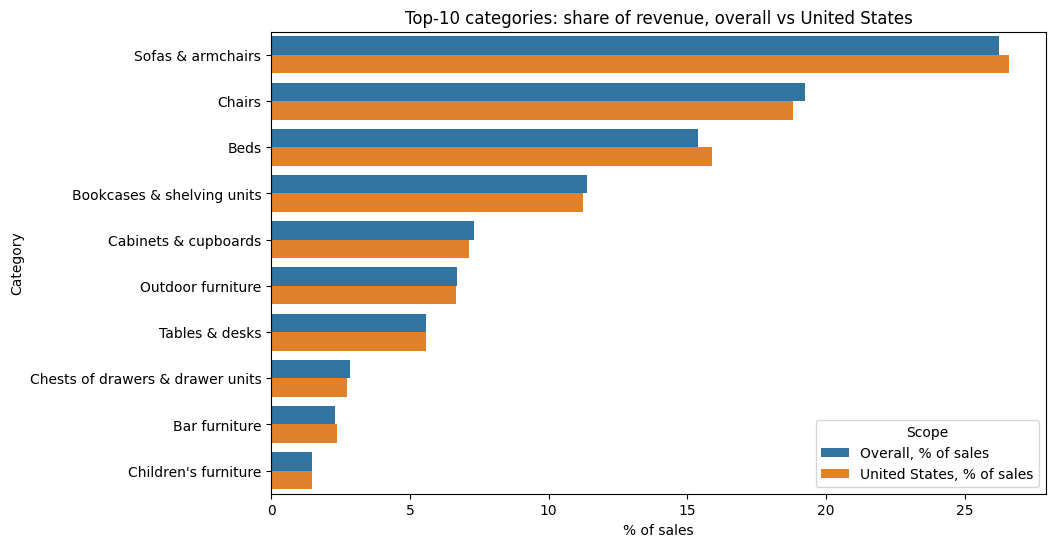


Device % share:
device
desktop    59.002245
mobile     38.734924
tablet      2.262831
Name: product_price, dtype: float64


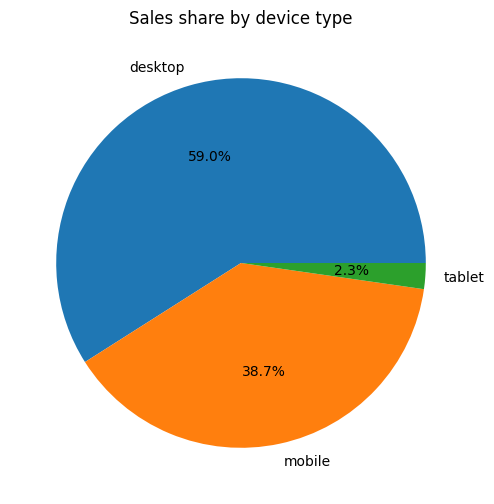


Top-10 models by sales, %:
mobile_model
Chrome        27.835602
<Other>       20.440966
Safari        20.302504
iPhone        20.082667
ChromeBook     5.725241
Edge           2.180746
iPad           1.403910
Firefox        1.316998
Pixel 4 XL     0.369976
Pixel 3        0.341390
Name: product_price, dtype: float64

Traffic % share:
traffic
(organic)         34.202840
(direct)          23.442345
<Other>           18.445594
(referral)        17.646386
(data deleted)     6.262836
Name: product_price, dtype: float64

Traffic channel % share:
traffic_channel
Organic Search    35.760189
Paid Search       26.620546
Direct            23.442345
Social Search      7.919827
Undefined          6.257093
Name: product_price, dtype: float64


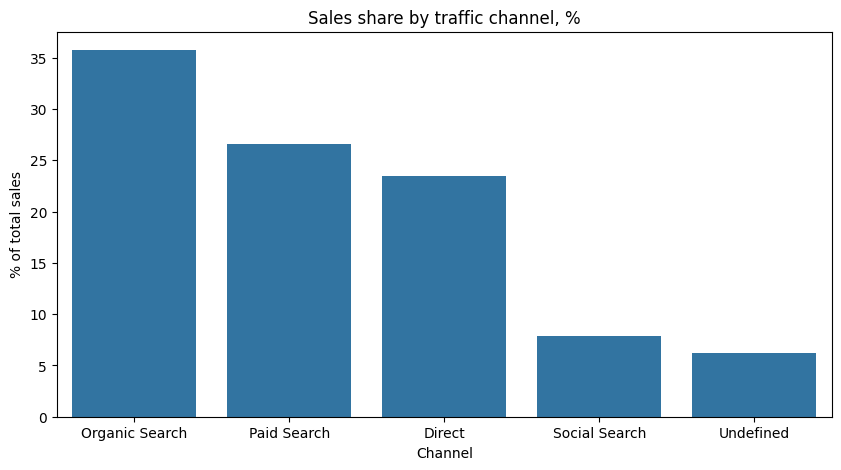


Registered users: 27945
Verified email, %: 71.69797817140812
Unsubscribed, %: 16.94399713723385

Sessions:
unsubscribed
0    23210
1     4735
Name: session_id, dtype: int64
Orders:
unsubscribed
0    2334
1     447
Name: product_price, dtype: int64
Total sales:
unsubscribed
0    2150796.9
1     431721.6
Name: product_price, dtype: float64
Conversion, %:
unsubscribed
0    10.056010
1     9.440338
dtype: float64
Conversion z-test: z = 1.290, p-value = 0.1971
Average order value: subscribed 922 | unsubscribed 966
Median order value:  subscribed 395 | unsubscribed 450
Order value Mann-Whitney: U = 500198, p-value = 0.1678

Countries with most registered users:
country
United States     12384
India              2687
Canada             2067
United Kingdom      859
France              553
Name: count, dtype: int64

Conversion by traffic channel:
traffic_channel
Social Search     9.729885
Direct            9.584429
Paid Search       9.584380
Undefined         9.584322
Organic Search    9.58087

In [3]:
#Top Continents and countries
continent_sales = df.groupby('continent')['product_price'].sum().sort_values(ascending=False).head(3)
continent_orders = df.groupby('continent')['product_price'].count().sort_values(ascending=False).head(3)
print('Top-3 continents by sales:')
print(continent_sales)
print('\nTop-3 continents by orders:')
print(continent_orders)

country_sales = df.groupby('country')['product_price'].sum().sort_values(ascending=False).head(5)
country_orders = df.groupby('country')['product_price'].count().sort_values(ascending=False).head(5)
print('\nTop-5 countries by sales:')
print(country_sales)
print('\nTop-5 countries by orders:')
print(country_orders)

plt.figure(figsize=(10, 5))
sns.barplot(x=country_sales.index, y=country_sales.values)
plt.title('Top-5 countries by sales')
plt.xlabel('Country')
plt.ylabel('Sales')
plt.show()

#Top-10 categories
category_sales = df.groupby('product_category')['product_price'].sum().sort_values(ascending=False).head(10)
category_orders = df.groupby('product_category')['product_price'].count().sort_values(ascending=False).head(10)
print('\nTop-10 categories by sales:')
print(category_sales)
print('\nTop-10 categories by orders:')
print(category_orders)

plt.figure(figsize=(10, 6))
sns.barplot(x=category_sales.index, y=category_sales.values)
plt.xticks(rotation = 90)
plt.title('Top-10 categories by sales')
plt.xlabel('Category')
plt.ylabel('Sales')
plt.show()

#Top-10 categories in top country vs overall
top_country = country_sales.index[0]
print(f"\nTop country by sales is {top_country}")

total_sales = df['product_price'].sum()
top_country_df = df[df['country'] == top_country]
top_country_total = top_country_df['product_price'].sum()

overall_share = df.groupby('product_category')['product_price'].sum() / total_sales * 100
country_share = top_country_df.groupby('product_category')['product_price'].sum() / top_country_total * 100

category_compare = pd.DataFrame({
    'Overall, % of sales': overall_share,
    f'{top_country}, % of sales': country_share
}).fillna(0)
category_compare['Difference, p.p.'] = category_compare[f'{top_country}, % of sales'] - category_compare['Overall, % of sales']
category_compare['Rank overall'] = category_compare['Overall, % of sales'].rank(ascending=False).astype(int)
category_compare[f'Rank {top_country}'] = category_compare[f'{top_country}, % of sales'].rank(ascending=False).astype(int)
category_compare = category_compare.sort_values('Overall, % of sales', ascending=False).head(10).round(2)
print('\nTop-10 categories: overall vs top country (% of revenue):')
display(category_compare)

top10_overall = set(overall_share.nlargest(10).index)
top10_country = set(country_share.nlargest(10).index)
print('Categories in both top-10 lists:', len(top10_overall & top10_country))

compare_plot = category_compare[['Overall, % of sales', f'{top_country}, % of sales']].reset_index().melt(
    id_vars='product_category', var_name='Scope', value_name='Share')
plt.figure(figsize=(10, 6))
sns.barplot(data=compare_plot, y='product_category', x='Share', hue='Scope')
plt.title(f'Top-10 categories: share of revenue, overall vs {top_country}')
plt.xlabel('% of sales')
plt.ylabel('Category')
plt.show()

#Device and model

device_sales = df.groupby('device')['product_price'].sum().sort_values(ascending=False)
print('\nDevice % share:')
print(device_sales / total_sales * 100)

plt.figure(figsize=(6, 6))
plt.pie(device_sales, labels=device_sales.index, autopct='%1.1f%%')
plt.title('Sales share by device type')
plt.show()

model_sales = df.groupby('mobile_model')['product_price'].sum().sort_values(ascending=False).head(10)
print('\nTop-10 models by sales, %:')
print(model_sales/total_sales * 100)

#Source and channel
source_sales = df.groupby('traffic')['product_price'].sum().sort_values(ascending=False)
print('\nTraffic % share:')
print(source_sales / total_sales * 100)

channel_sales = df.groupby('traffic_channel')['product_price'].sum().sort_values(ascending=False)
print('\nTraffic channel % share:')
print(channel_sales / total_sales * 100)

channel_share_df = (channel_sales / total_sales * 100).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=channel_share_df, x='traffic_channel', y='product_price')
plt.title('Sales share by traffic channel, %')
plt.xlabel('Channel')
plt.ylabel('% of total sales')
plt.show()

#Users
users = df.dropna(subset=['account_id'])
users = users.drop_duplicates(subset='account_id')

print('\nRegistered users:', len(users))
print('Verified email, %:', users['verified'].mean() * 100)
print('Unsubscribed, %:', users['unsubscribed'].mean() * 100)

#Behaviour
# Without Jan 28-31 (no orders)
registered = df[(df['account_id'].notna()) & (df['session_date'] < '2021-01-28')]

sessions_by_group = registered.groupby('unsubscribed')['session_id'].nunique()
orders_by_group = registered.groupby('unsubscribed')['product_price'].count()

print('\nSessions:')
print(sessions_by_group)
print('Orders:')
print(orders_by_group)
print('Total sales:')
print(registered.groupby('unsubscribed')['product_price'].sum())
print('Conversion, %:')
print(orders_by_group / sessions_by_group * 100)

#Conversion test
z_stat, p_conv = proportions_ztest(count=orders_by_group, nobs=sessions_by_group)
print(f'Conversion z-test: z = {z_stat:.3f}, p-value = {p_conv:.4f}')

#Average order value test
aov_sub = registered[registered['unsubscribed'] == 0]['product_price'].dropna()
aov_unsub = registered[registered['unsubscribed'] == 1]['product_price'].dropna()
print(f'Average order value: subscribed {aov_sub.mean():.0f} | unsubscribed {aov_unsub.mean():.0f}')
print(f'Median order value:  subscribed {aov_sub.median():.0f} | unsubscribed {aov_unsub.median():.0f}')

u_stat, p_aov = stats.mannwhitneyu(aov_sub, aov_unsub, alternative='two-sided')
print(f'Order value Mann-Whitney: U = {u_stat:.0f}, p-value = {p_aov:.4f}')

#Countries with most registered users
print('\nCountries with most registered users:')
print(users['country'].value_counts().head(5))

#EXTRA
#Conversion by traffic channel
orders_by_channel = df.groupby('traffic_channel')['product_price'].count()
sessions_by_channel = df.groupby('traffic_channel')['session_id'].nunique()

print('\nConversion by traffic channel:')
print((orders_by_channel / sessions_by_channel * 100).sort_values(ascending=False))

#Avg order value by device
print('\nAvg order value by device:')
print(df.groupby('device')['product_price'].mean().sort_values(ascending=False))

#Browser share of sales
browser_sales = df.groupby('browser')['product_price'].sum().sort_values(ascending=False)

print('\nBrowser % share of sales:')
print(browser_sales / total_sales * 100)

**Sales by geography**

Americas dominate with 17.7M USD and 18,553 orders, which is 55% of total revenue and more than Asia (7.6M USD) and Europe (5.9M USD) combined. The top 3 continents together generate about 98% of sales, while Africa and Oceania remain marginal.

At country level, the United States alone brings 13.9M USD (14,673 orders), which is about 44% of all revenue and nearly 80% of the Americas total. India (2.8M USD) and Canada (2.4M USD) follow at a distance, while the UK (0.9M USD) and France (0.7M USD) close the top 5. Together these five countries account for about 65% of revenue.

The ranking by orders mirrors the ranking by sales exactly, and the average order value stays in a narrow range of 910 to 1,050 USD across all leaders. Differences between markets come from order volume, not from basket size. The business is heavily dependent on the US market, which is both its main strength and its main concentration risk.

**Product categories**

Sofas and armchairs lead in revenue with 8.4M USD, or 26% of all sales, followed by chairs (6.1M USD, 19%) and beds (4.9M USD, 15%). These three categories alone generate 61% of revenue. The ranking by orders looks different: bookcases and shelving units are the most frequently bought category with 7,630 orders, but they rank only fourth by revenue (3.6M USD, 11%). The reason is price: an average sofa order is about 1,950 USD and a bed about 1,680 USD, while a bookcase order is about 480 USD and children's furniture about 275 USD.

In the United States, the top country by sales, the revenue structure by category repeats the overall one almost exactly. Both top-10 lists contain the same categories in the same order, and the largest differences in share are below half a percentage point: beds +0.48 p.p. (15.9% vs 15.4%), chairs −0.44 p.p. (18.8% vs 19.2%) and sofas +0.35 p.p. (26.6% vs 26.2%). The top 3 categories bring 61.3% of US revenue versus 60.9% overall. The leading market therefore has no product preferences of its own, which is expected since the US makes up about 44% of all sales. Overall, revenue is driven by a few expensive categories, while cheaper ones bring traffic and order volume.

**Devices and browsers**

Desktop brings 59% of revenue, mobile 39% and tablet only 2%. Average order value is close across devices, from 944 USD on mobile to 1,001 USD on tablet, so the gap in revenue comes from the number of orders, not from basket size. By browser, Chrome dominates with 68% of sales and Safari takes 24%, while all others together stay below 9%. The mobile_model column mostly contains browser names (Chrome, Safari, Other) instead of device models, so it is not reliable for analysis. In practice, the site should be optimised first for desktop and mobile Chrome and Safari, which together cover the vast majority of buyers.

**Traffic sources**

Organic search is the largest channel with 36% of revenue, followed by paid search (27%) and direct traffic (23%). Social search brings 8% and undefined traffic 6%. Conversion is practically identical across all channels, from 9.58% to 9.73%, so channels differ only in the volume of traffic they bring, not in its quality. A noticeable part of traffic is marked as data deleted (6%) or Other (18%), which limits detailed source analysis. Growth here depends on attracting more traffic, since every channel converts equally well.

**Registered users and email subscriptions**

There are 27,945 registered users. 71.7% of them verified their email and 16.9% unsubscribed from the mailing. The geography of registrations mirrors sales: the United States accounts for 12,384 users, about 44%, followed by India, Canada, the UK and France.

Unsubscribed users convert slightly worse than subscribed ones (9.4% vs 10.1%), but a z-test for two proportions shows that this difference is not statistically significant (z = 1.29, p = 0.197). Their average order value is slightly higher (966 USD vs 922 USD, median 450 vs 395 USD). Order values are strongly skewed (the mean is more than twice the median), so the Mann-Whitney U test was used, and this difference is not significant either (p = 0.168). Both groups also generate revenue in proportion to their size: subscribed users make up 83.1% of registered sessions and bring 83.3% of registered revenue.

Unsubscribing from the mailing therefore does not change purchasing behaviour, so an unsubscribed user is not a lost buyer. The subscribed base of over 23,000 users remains the main audience for email campaigns.

**Data cleaning for per-day analysis.** January 28–31 contain sessions but no orders, which means the order data is incomplete at the end of the period. These 4 days are excluded from all per-day calculations below.

In [4]:
#Data without Jan 28-31 (no orders)
df_clean = df[df['session_date'] < '2021-01-28']
df_known_clean = df_clean[df_clean['traffic_channel'] != 'Undefined']

print('Days in full data:', df['session_date'].nunique())
print('Days after excluding Jan 28–31:', df_clean['session_date'].nunique())

Days in full data: 92
Days after excluding Jan 28–31: 88


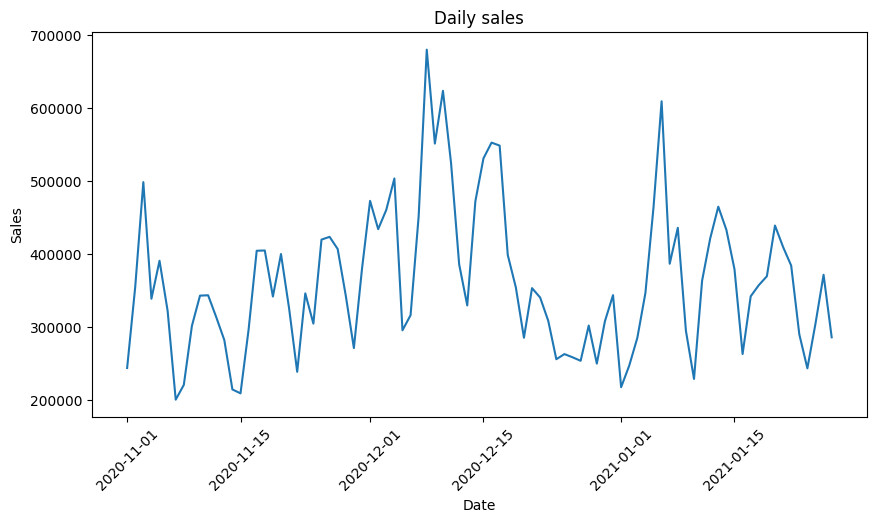


Highest prices by days:
   session_date  product_price
37   2020-12-08       680509.5
39   2020-12-10       624104.6
66   2021-01-06       609763.8
45   2020-12-16       553134.9
38   2020-12-09       551811.6

Lowest prices by days:
   session_date  product_price
6    2020-11-07       200892.2
14   2020-11-15       209535.5
13   2020-11-14       214889.3
61   2021-01-01       217984.9
7    2020-11-08       221162.5

Monthly sales:
      month  product_price
0  December     12423439.3
1   January      9650776.8
2  November      9897515.0

Average sales per weekday:
           days  avg_sales_per_day
weekday                           
Monday       13           356638.0
Tuesday      13           419809.0
Wednesday    13           420503.0
Thursday     12           411411.0
Friday       12           376922.0
Saturday     12           289833.0
Sunday       13           267184.0


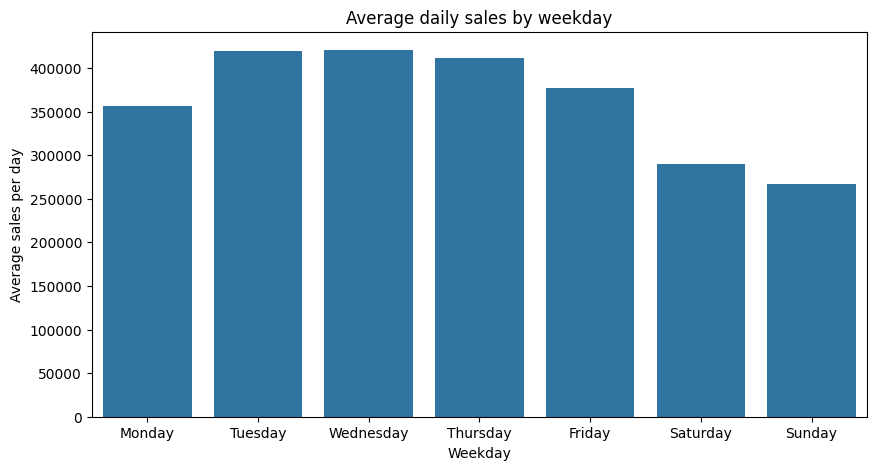


Continents:
['Americas' 'Europe' 'Africa' 'Asia' 'Oceania' '(not set)']
  continent  product_price
0  Americas     17665280.0
1      Asia      7601298.3
2    Europe      5934624.2


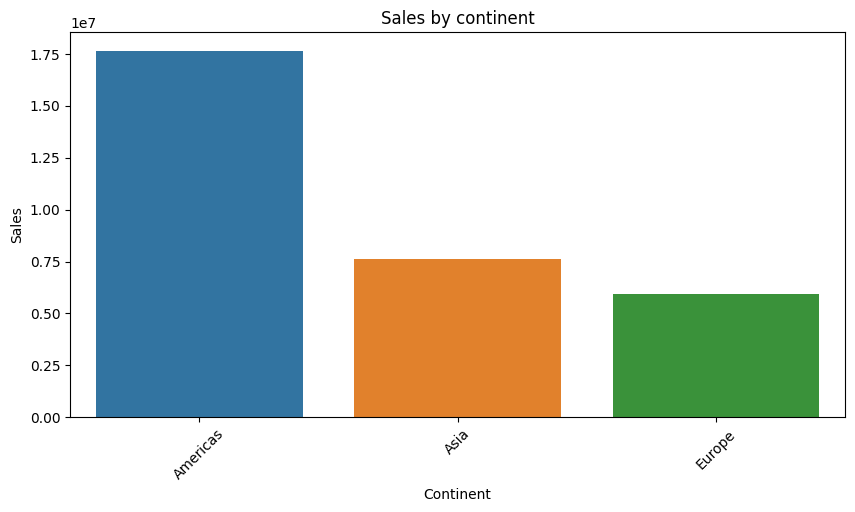


Total sales by channel:
  traffic_channel  product_price
0          Direct      7494923.4
1  Organic Search     11433151.6
2     Paid Search      8511049.4
3   Social Search      2532105.7
4       Undefined      2000501.0


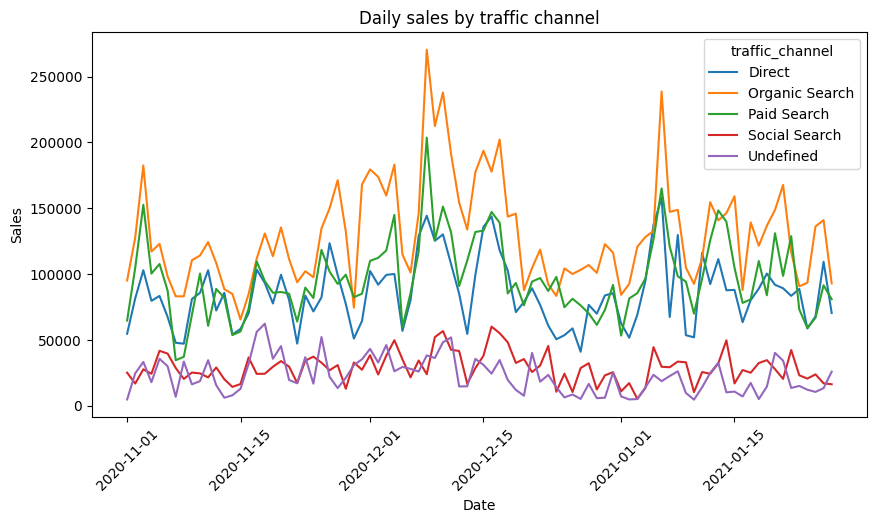

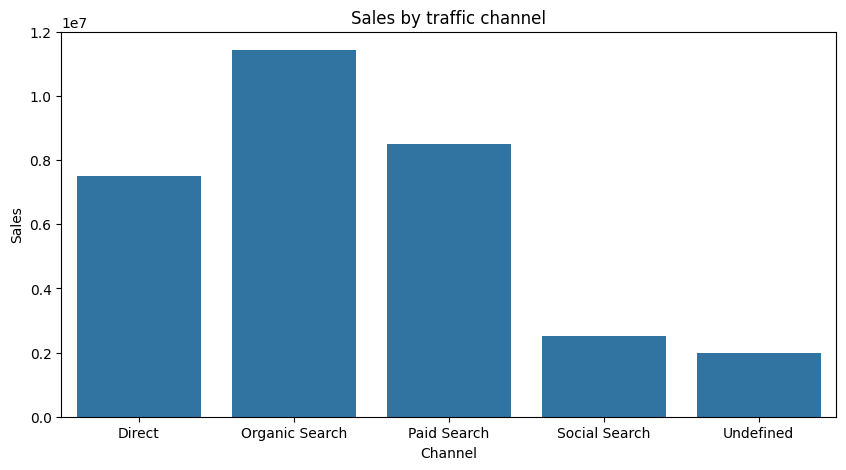


Total sales by device:
    device  product_price
0  desktop     18864039.0
1   mobile     12384225.8
2   tablet       723466.3


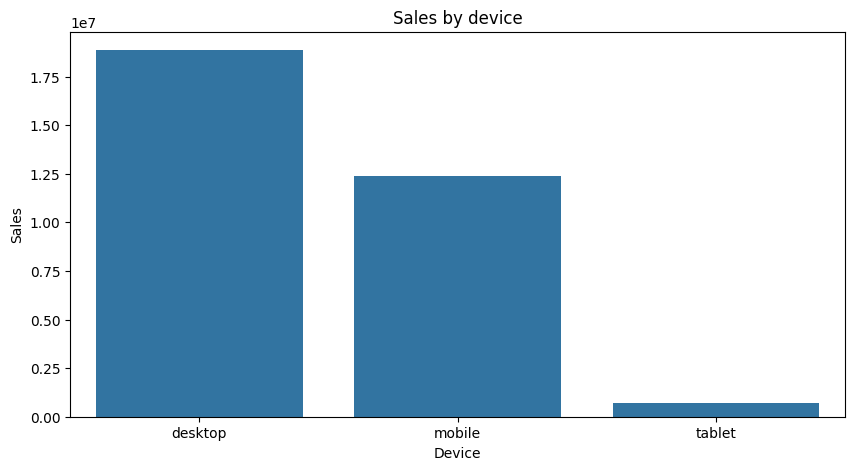

In [5]:
daily_sales = df_clean.groupby('session_date')['product_price'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=daily_sales, x='session_date', y='product_price')
plt.xticks(rotation=45)
plt.title('Daily sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

print('\nHighest prices by days:')
print(daily_sales.sort_values(by='product_price', ascending=False).head(5))
print('\nLowest prices by days:')
print(daily_sales.sort_values(by='product_price', ascending=True).head(5))

#Season
df['month'] = df['session_date'].dt.month_name()
monthly_sales = df.groupby('month')['product_price'].sum().reset_index()
month_order = ['November', 'December', 'January']
print('\nMonthly sales:')
print(monthly_sales)

#Average sales by weekday
daily_sales['weekday'] = daily_sales['session_date'].dt.day_name()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_sales = daily_sales.groupby('weekday')['product_price'].agg(['count', 'mean']).reindex(day_order)
weekday_sales = weekday_sales.rename(columns={'count': 'days', 'mean': 'avg_sales_per_day'})
print('\nAverage sales per weekday:')
print(weekday_sales.round(0))

plt.figure(figsize=(10, 5))
sns.barplot(x=weekday_sales.index, y=weekday_sales['avg_sales_per_day'])
plt.title('Average daily sales by weekday')
plt.xlabel('Weekday')
plt.ylabel('Average sales per day')
plt.show()

#Continents
print('\nContinents:')
print(df['continent'].unique())

continents = ['Americas', 'Asia', 'Europe']
df_continents = df[df['continent'].isin(continents)]
continent_sales = df_continents.groupby('continent')['product_price'].sum().reset_index()
print(continent_sales)

plt.figure(figsize=(10, 5))
sns.barplot(data=continent_sales, x='continent', y='product_price', hue='continent')
plt.xticks(rotation=45)
plt.title('Sales by continent')
plt.xlabel('Continent')
plt.ylabel('Sales')
plt.show()

#Channel

channel_daily_sales = df_clean.groupby(['traffic_channel', 'session_date'])['product_price'].sum().reset_index()
channel_sales = df.groupby('traffic_channel')['product_price'].sum().reset_index()
print('\nTotal sales by channel:')
print(channel_sales)

plt.figure(figsize=(10, 5))
sns.lineplot(data=channel_daily_sales, x='session_date', y='product_price', hue='traffic_channel')
plt.xticks(rotation=45)
plt.title('Daily sales by traffic channel')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=channel_sales, x='traffic_channel', y='product_price')
plt.title('Sales by traffic channel')
plt.xlabel('Channel')
plt.ylabel('Sales')
plt.show()

#Device
device_daily_sales = df.groupby(['device', 'session_date'])['product_price'].sum().reset_index()
device_sales = df.groupby('device')['product_price'].sum().reset_index()
print('\nTotal sales by device:')
print(device_sales)

plt.figure(figsize=(10, 5))
sns.barplot(data=device_sales, x='device', y='product_price')
plt.title('Sales by device')
plt.xlabel('Device')
plt.ylabel('Sales')
plt.show()

**Sales dynamics**

December is the strongest month with 12.4M USD, compared to 9.9M USD in November and 9.7M USD in January. Four of the five best days fall in December, with the absolute peak on December 8 (681K USD), followed by December 10 and December 9, which points to pre-holiday demand in the first half of the month. January 6 is the only January day in the top 5 (610K USD), showing a quick recovery after the holidays.

January 28 to 31 contain sessions but no orders, which reflects incomplete data at the end of the period rather than a real drop in demand. These four days are therefore excluded from all per-day calculations, leaving 88 days in the analysis, and the January total covers only 27 days. On a per-day basis, January averages about 357K USD, which is lower than December (401K USD) but higher than November (330K USD). The lowest day is November 7 (201K USD).

By day of week, average daily sales are compared, because the period contains 13 Sundays, Mondays, Tuesdays and Wednesdays but only 12 Thursdays, Fridays and Saturdays. Midweek is the strongest part of the week: Wednesday (421K USD), Tuesday (420K USD) and Thursday (411K USD) are almost equal. Comparing totals hid this, since Thursday looked about 10% weaker only because the period has one Thursday fewer. Monday (357K USD) and Friday (377K USD) are in between. Weekends are clearly weaker: Saturday averages 290K USD and Sunday 267K USD, about 33% less than midweek. Customers buy furniture mainly on working days, so promotions and email campaigns are likely to be most effective from Tuesday to Thursday, while the weekend is the natural window for traffic-building activity.

In [6]:
print(df['traffic_channel'].unique())
print(df['device'].unique())

df_known = df[df['traffic_channel'] != 'Undefined']
print(df_known['traffic_channel'].unique())
print('Rows removed:', len(df) - len(df_known))

sessions_pivot = pd.pivot_table(
    df_known,
    index='traffic_channel',
    columns='device',
    values='session_id',
    aggfunc='nunique'
)
sessions_pivot


['Paid Search' 'Organic Search' 'Direct' 'Undefined' 'Social Search']
['desktop' 'mobile' 'tablet']
['Paid Search' 'Organic Search' 'Direct' 'Social Search']
Rows removed: 21483


device,desktop,mobile,tablet
traffic_channel,,,
Direct,47825,31745,1812
Organic Search,72622,49014,2789
Paid Search,55167,37034,2140
Social Search,16288,10988,638


Sessions by traffic channel and device

After removing sessions with an undefined traffic channel (21,483 rows, about 6% of the data), 328,062 sessions remain. Desktop accounts for 58.5% of them, mobile for 39.3% and tablet for only 2.2%. Organic search is the largest channel with 124,425 sessions (38%), followed by paid search (29%), direct traffic (25%) and social search (9%).

The largest single segment is organic search on desktop with 72,622 sessions, about 22% of all traffic. The device mix is almost identical across channels: in every channel mobile brings about 67 sessions per 100 desktop sessions, and tablet stays at around 2%. The way users reach the site does not change the device they use, so traffic channels differ only in volume, not in audience structure.

Combined with the equal conversion rates across channels and the similar order values across devices, this means the audience behaves consistently regardless of how and from where it arrives. The main growth lever is therefore the overall volume of traffic, with organic and paid search on desktop and mobile as the key segments to develop.

In [7]:
#Sales top-10 in countries top-5
top_categories = df.groupby('product_category')['product_price'].sum().nlargest(10).index
top_countries = df.groupby('country')['product_price'].sum().nlargest(5).index

df_top = df[df['product_category'].isin(top_categories)]
df_top = df_top[df_top['country'].isin(top_countries)]

sales_pivot = pd.pivot_table(
    df_top,
    index='product_category',
    columns='country',
    values='product_price',
    aggfunc='sum'
)
sales_pivot


country,Canada,France,India,United Kingdom,United States
product_category,,,,,
Bar furniture,51724.0,11199.0,57657.0,22103.0,330805.0
Beds,354772.0,116414.0,358319.5,133816.0,2213058.0
Bookcases & shelving units,278981.9,73830.0,364507.4,113987.6,1567606.9
Cabinets & cupboards,181802.0,59101.5,191888.0,71684.5,994545.5
Chairs,417740.8,134029.4,544309.2,188519.4,2619773.8
Chests of drawers & drawer units,71952.0,21544.5,73111.0,36784.0,382388.0
Children's furniture,30264.0,14258.0,39177.0,13348.0,207575.0
Outdoor furniture,185322.8,40486.4,162289.4,57002.4,929245.2
Sofas & armchairs,692427.5,187735.0,788430.0,234812.0,3707144.5


Category structure in the top 5 countries

Sofas and armchairs are the leading category in every one of the top 5 countries, taking between 25.5% (UK) and 28.9% (Canada) of each country's revenue from the top 10 categories. Chairs are second everywhere with 17 to 21%, and beds are third in four countries with 13 to 17%. The only exception is India, where bookcases and shelving units (365K USD) slightly overtake beds (358K USD) and reach 13% of sales, the highest share of this category among the five countries.

Other differences are small. Canada spends a bit more on outdoor furniture (7.7% vs 6 to 7% elsewhere), and India a bit more on tables and desks (6.7%). The United States, with 13.7M USD, follows the overall structure almost exactly: sofas 27%, chairs 19%, beds 16%, bookcases 11%.

The product mix is nearly identical across markets, and the countries differ mainly in total volume, not in what customers buy. This means one assortment and marketing strategy can work for all key countries without strong local adaptation, with a possible exception for bookcases in India and outdoor furniture in Canada.

In [8]:
#Sales by continent vs device
continent_device = pd.pivot_table(
    df,
    index='continent',
    columns='device',
    values='product_price',
    aggfunc='sum'
)
continent_device

device,desktop,mobile,tablet
continent,,,
(not set),51643.4,22354.0,70.0
Africa,193643.2,130677.8,6910.0
Americas,10497307.4,6780364.3,387608.3
Asia,4381094.4,3028054.4,192149.5
Europe,3493992.9,2311532.8,129098.5
Oceania,246357.7,111242.5,7630.0


Sales by continent and device

The device split is very similar across the main markets. In the Americas desktop brings 59% of sales, mobile 38% and tablet 2%. Europe shows almost the same structure (59%, 39%, 2%), as do Asia (58%, 40%, 3%) and Africa (58%, 39%, 2%). Asia has the highest mobile share among the large regions, but the difference from the others is only about 1 to 2 percentage points.

Oceania is the only noticeable exception: desktop accounts for 67% of its sales and mobile for only 30%, so customers there rely on desktop more than anywhere else. However, Oceania brings just 0.37M USD in total, so this has little effect on overall results. Tablet stays at around 2% of sales in every region, which makes it a minor channel everywhere.

Overall, the role of devices does not depend on geography: desktop is the main sales channel in every market, and mobile consistently provides about 40% of revenue. The site experience on both desktop and mobile is equally important for all regions, with no need for separate regional priorities.

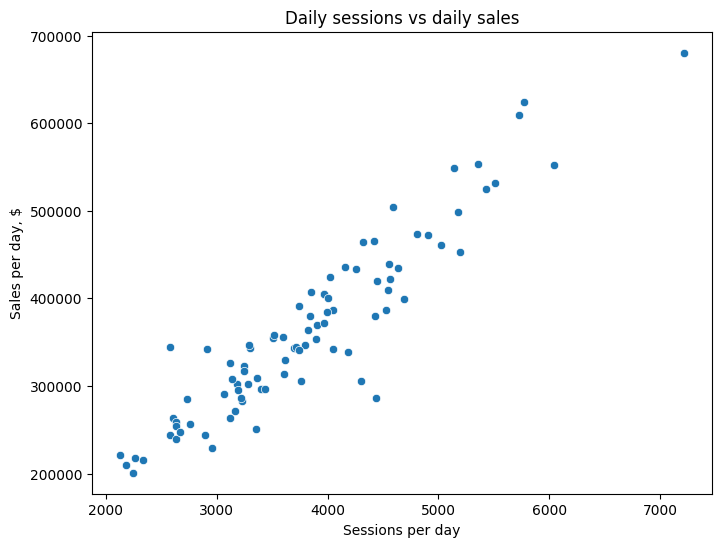

Sessions: ShapiroResult(statistic=np.float64(0.9701004812858438), pvalue=np.float64(0.03948838648168485))
Sales: ShapiroResult(statistic=np.float64(0.9563431707174843), pvalue=np.float64(0.0047925668386651875))
Pearson: PearsonRResult(statistic=np.float64(0.9313146607045041), pvalue=np.float64(1.7394621412998283e-39))
Spearman: SignificanceResult(statistic=np.float64(0.904283047444613), pvalue=np.float64(1.5381769633064087e-33))


In [9]:
#Sessions vs sales per date
daily = df_clean.groupby('session_date').agg({'session_id': 'nunique', 'product_price': 'sum'}).reset_index()
daily = daily.rename(columns={'session_id': 'sessions', 'product_price': 'sales'})
daily.head()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=daily, x='sessions', y='sales')
plt.title('Daily sessions vs daily sales')
plt.xlabel('Sessions per day')
plt.ylabel('Sales per day, $')
plt.show()

print('Sessions:', stats.shapiro(daily['sessions']))
print('Sales:', stats.shapiro(daily['sales']))

print('Pearson:', stats.pearsonr(daily['sessions'], daily['sales']))
print('Spearman:', stats.spearmanr(daily['sessions'], daily['sales']))

**Correlation between sessions and sales**

January 28 to 31 were excluded from this analysis, since they contain sessions but no orders and would distort the relationship, leaving 88 days. Neither sessions (p = 0.039) nor sales (p = 0.005) are normally distributed, so Spearman is used as the main method. The correlation is strong and significant: Spearman 0.90 with p far below 0.001. Pearson is even higher at 0.93, which shows that the relationship is close to linear: each additional visitor adds roughly the same amount of revenue. Before the incomplete days were excluded, Pearson was only 0.79, which shows how strongly four outlier days distorted the result. Overall, revenue is driven by traffic volume, and with conversion stable at about 9.6%, more visitors directly means more sales.

Americas ShapiroResult(statistic=np.float64(0.9705574058095676), pvalue=np.float64(0.042468562628999736))
Asia ShapiroResult(statistic=np.float64(0.9379344563134144), pvalue=np.float64(0.0003820857396580246))
Europe ShapiroResult(statistic=np.float64(0.9591945303470173), pvalue=np.float64(0.007309892924070338))


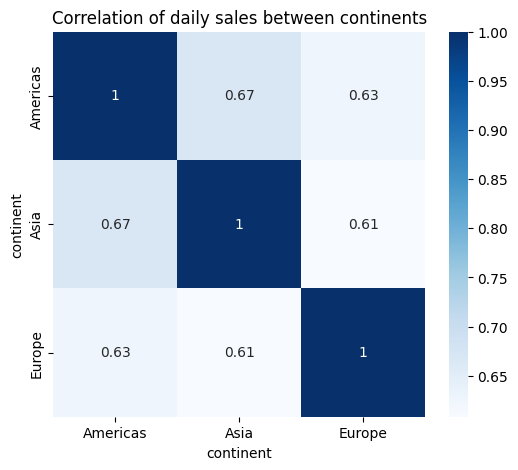

Coefficients:
[[1.         0.66853933 0.62588496]
 [0.66853933 1.         0.60822092]
 [0.62588496 0.60822092 1.        ]]
p-values:
[[0.00000000e+00 1.10010597e-12 7.00905296e-11]
 [1.10010597e-12 0.00000000e+00 3.27313841e-10]
 [7.00905296e-11 3.27313841e-10 0.00000000e+00]]
PearsonRResult(statistic=np.float64(0.6922725921166172), pvalue=np.float64(8.004062946873881e-14))
PearsonRResult(statistic=np.float64(0.6695272265974656), pvalue=np.float64(9.911408291629347e-13))
PearsonRResult(statistic=np.float64(0.6677857678141951), pvalue=np.float64(1.1908929032637074e-12))


In [10]:
#Sales correlation between top-3 continents
top_continents = df.groupby('continent')['product_price'].sum().nlargest(3).index

df_cont = df_clean[df_clean['continent'].isin(top_continents)]

continent_daily = pd.pivot_table(
    df_cont,
    index='session_date',
    columns='continent',
    values='product_price',
    aggfunc='sum'
)
continent_daily = continent_daily.fillna(0)
continent_daily.head()

for continent in continent_daily.columns:
    print(continent, stats.shapiro(continent_daily[continent]))

continent_corr = continent_daily.corr(method='spearman')

plt.figure(figsize=(6, 5))
sns.heatmap(continent_corr, annot=True, cmap='Blues')
plt.title('Correlation of daily sales between continents')
plt.show()

result = stats.spearmanr(continent_daily)
print('Coefficients:')
print(result.statistic)
print('p-values:')
print(result.pvalue)

print(stats.pearsonr(continent_daily['Americas'], continent_daily['Asia']))
print(stats.pearsonr(continent_daily['Americas'], continent_daily['Europe']))
print(stats.pearsonr(continent_daily['Asia'], continent_daily['Europe']))

**Correlation of daily sales between continents**

January 28 to 31 were excluded, since all continents show zero sales on these days because of incomplete data, which artificially strengthened the correlation. Daily sales are not normally distributed in any of the three continents (Americas p = 0.042, Asia p < 0.001, Europe p = 0.007), so Spearman is used as the main method. All pairs show a moderate positive correlation that is statistically significant (p far below 0.001): Americas and Asia 0.67, Americas and Europe 0.63, Asia and Europe 0.61. Pearson gives similar values (0.67 to 0.69). Before the incomplete days were excluded, the coefficients were 0.66 to 0.71 and looked strong, so part of that link came from the shared zero days. Overall, sales in the three main regions tend to rise and fall on the same days, which points to shared drivers like global seasonality, holidays and company-wide campaigns. Still, the link is only moderate, so each region also has a noticeable share of its own daily variation, driven by local factors.

Direct ShapiroResult(statistic=np.float64(0.9627333315701925), pvalue=np.float64(0.012486076318203962))
Organic Search ShapiroResult(statistic=np.float64(0.9267870193583199), pvalue=np.float64(9.599991143695942e-05))
Paid Search ShapiroResult(statistic=np.float64(0.9649007192209844), pvalue=np.float64(0.017435847676207643))
Social Search ShapiroResult(statistic=np.float64(0.9766690958935521), pvalue=np.float64(0.1130966509154806))


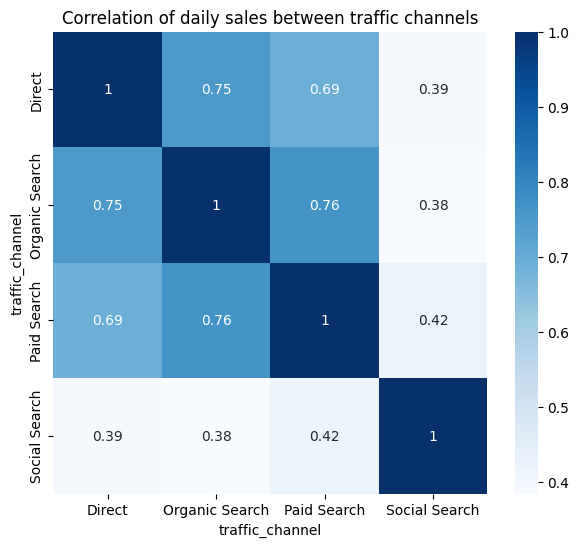

Index(['Direct', 'Organic Search', 'Paid Search', 'Social Search'], dtype='object', name='traffic_channel')
p-values:
[[0.00000000e+00 5.36254724e-17 9.50545893e-14 1.47827068e-04]
 [5.36254724e-17 0.00000000e+00 4.86349318e-18 2.14393938e-04]
 [9.50545893e-14 4.86349318e-18 0.00000000e+00 4.54377940e-05]
 [1.47827068e-04 2.14393938e-04 4.54377940e-05 0.00000000e+00]]


In [11]:
#Sales correlation between traffic channels
channel_daily = pd.pivot_table(
    df_known_clean,
    index='session_date',
    columns='traffic_channel',
    values='product_price',
    aggfunc='sum'
)
channel_daily = channel_daily.fillna(0)

for channel in channel_daily.columns:
    print(channel, stats.shapiro(channel_daily[channel]))

channel_corr = channel_daily.corr(method='spearman')

plt.figure(figsize=(7, 6))
sns.heatmap(channel_corr, annot=True, cmap='Blues')
plt.title('Correlation of daily sales between traffic channels')
plt.show()

result = stats.spearmanr(channel_daily)
print(channel_daily.columns)
print('p-values:')
print(result.pvalue)

**Correlation of daily sales between traffic channels**

January 28 to 31 were excluded because of incomplete data, and the Undefined channel was not included. Daily sales are not normally distributed for Direct (p = 0.012), Organic Search (p < 0.001) and Paid Search (p = 0.017), while Social Search is close to normal (p = 0.113). Since most channels deviate from normality, Spearman is used. All six pairs show a statistically significant positive correlation (p < 0.001). The strongest links are between the three large channels: Organic and Paid Search …, Direct and Organic …, Direct and Paid …, which is a … correlation. Social Search is connected to the other channels more weakly (… to …). Overall, the main channels rise and fall on the same days, which points to common demand drivers such as seasonality and overall traffic, while Social Search follows its own rhythm more.

Beds ShapiroResult(statistic=np.float64(0.9502172398839275), pvalue=np.float64(0.001990313417105756))
Bookcases & shelving units ShapiroResult(statistic=np.float64(0.9604356648389608), pvalue=np.float64(0.008807256782666481))
Cabinets & cupboards ShapiroResult(statistic=np.float64(0.9561694649352347), pvalue=np.float64(0.004672141747344718))
Chairs ShapiroResult(statistic=np.float64(0.9426548736704264), pvalue=np.float64(0.0007083935880594534))
Sofas & armchairs ShapiroResult(statistic=np.float64(0.9625642232396963), pvalue=np.float64(0.012167254393811892))


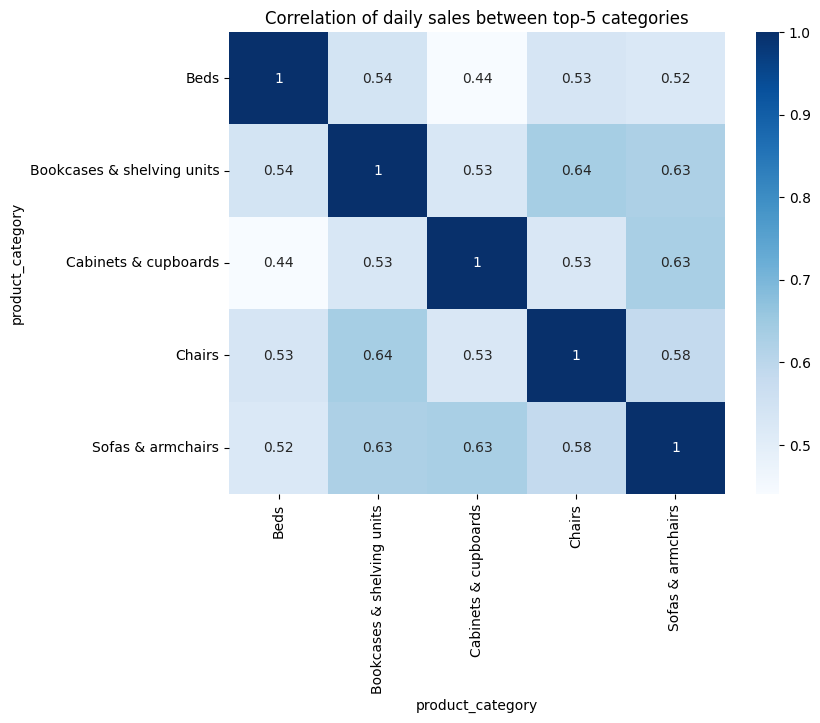

Index(['Beds', 'Bookcases & shelving units', 'Cabinets & cupboards', 'Chairs',
       'Sofas & armchairs'],
      dtype='object', name='product_category')
p-values:
[[0.00000000e+00 4.69083172e-08 1.75878304e-05 7.91341555e-08
  1.86436772e-07]
 [4.69083172e-08 0.00000000e+00 1.19061296e-07 2.58543758e-11
  7.18899090e-11]
 [1.75878304e-05 1.19061296e-07 0.00000000e+00 1.34491526e-07
  4.32290827e-11]
 [7.91341555e-08 2.58543758e-11 1.34491526e-07 0.00000000e+00
  2.46282006e-09]
 [1.86436772e-07 7.18899090e-11 4.32290827e-11 2.46282006e-09
  0.00000000e+00]]


,pair,spearman_r,strength,p_value,significant
5,Bookcases & shelving units – Chairs,0.64,moderate,2.585438e-11,True
6,Bookcases & shelving units – Sofas & armchairs,0.63,moderate,7.188991e-11,True
8,Cabinets & cupboards – Sofas & armchairs,0.63,moderate,4.322908e-11,True
9,Chairs – Sofas & armchairs,0.58,moderate,2.462820e-09,True
0,Beds – Bookcases & shelving units,0.54,moderate,4.690832e-08,True
2,Beds – Chairs,0.53,moderate,7.913416e-08,True
7,Cabinets & cupboards – Chairs,0.53,moderate,1.344915e-07,True
4,Bookcases & shelving units – Cabinets & cupboards,0.53,moderate,1.190613e-07,True
3,Beds – Sofas & armchairs,0.52,moderate,1.864368e-07,True
1,Beds – Cabinets & cupboards,0.44,moderate,1.758783e-05,True


In [12]:
#Sales correlation between top-5 categories
top_categories = df.groupby('product_category')['product_price'].sum().nlargest(5).index
df_cat = df_clean[df_clean['product_category'].isin(top_categories)]

category_daily = pd.pivot_table(
    df_cat,
    index='session_date',
    columns='product_category',
    values='product_price',
    aggfunc='sum'
)
category_daily = category_daily.fillna(0)

for category in category_daily.columns:
    print(category, stats.shapiro(category_daily[category]))

category_corr = category_daily.corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(category_corr, annot=True, cmap='Blues')
plt.title('Correlation of daily sales between top-5 categories')
plt.show()

result = stats.spearmanr(category_daily)
print(category_daily.columns)
print('p-values:')
print(result.pvalue)

#Correlation strength by pairs
def corr_strength(r):
    if abs(r) < 0.3:
        return 'weak'
    elif abs(r) < 0.7:
        return 'moderate'
    else:
        return 'strong'

pairs = []
for cat_1, cat_2 in itertools.combinations(category_daily.columns, 2):
    r, p = stats.spearmanr(category_daily[cat_1], category_daily[cat_2])
    pairs.append({'pair': f'{cat_1} – {cat_2}', 'spearman_r': round(r, 2),
                  'strength': corr_strength(r), 'p_value': p, 'significant': p < 0.05})

category_pairs = pd.DataFrame(pairs).sort_values('spearman_r', ascending=False)
category_pairs

**Correlation of daily sales between top-5 categories**

Daily sales are not normally distributed in any of the top 5 categories (p from 0.001 to 0.012), so Spearman is used. All ten pairs show a moderate positive correlation, with coefficients from 0.44 to 0.64. All of them are statistically significant (p < 0.001), which means the relationships are not random, although the p-value says nothing about their strength. The strongest links are between bookcases and chairs (0.64), bookcases and sofas (0.63), and cabinets and sofas (0.63). The weakest is between beds and cabinets (0.44). Beds show the lowest correlation with every other category (0.44 to 0.54), so their daily sales are the most independent, which is expected for a large, planned purchase. Overall, sales of different categories tend to rise and fall on the same days, so demand is partly driven by common factors like overall traffic and seasonality. Since the links are only moderate, each category also keeps a noticeable share of its own daily variation.

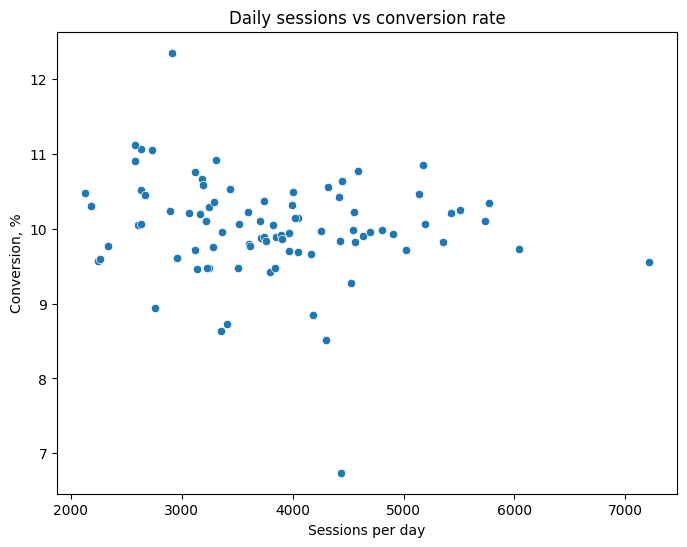

ShapiroResult(statistic=np.float64(0.8964456869962478), pvalue=np.float64(3.5101107273794467e-06))
SignificanceResult(statistic=np.float64(-0.1304110457539361), pvalue=np.float64(0.22587557493278324))


In [13]:
#Daily sessions vs conversion rate
daily_orders = df_clean.groupby('session_date')['product_price'].count().reset_index()
daily_orders = daily_orders.rename(columns={'product_price': 'orders'})

daily = pd.merge(daily, daily_orders, on='session_date')
daily['conversion'] = daily['orders'] / daily['sessions'] * 100
daily.head()
plt.figure(figsize=(8, 6))
sns.scatterplot(data=daily, x='sessions', y='conversion')
plt.title('Daily sessions vs conversion rate')
plt.xlabel('Sessions per day')
plt.ylabel('Conversion, %')
plt.show()

print(stats.shapiro(daily['conversion']))
print(stats.spearmanr(daily['sessions'], daily['conversion']))

**Correlation between sessions and conversion per day**

January 28 to 31 were excluded, since zero orders on these days gave an artificial 0% conversion. Daily conversion is not normally distributed (p < 0.001), so Spearman is used. The coefficient is −0.13 with p = 0.23, so the link is weak and not statistically significant. Before the incomplete days were excluded, the distribution was much further from normal (Shapiro-Wilk statistic 0.46 vs 0.90 now), which shows how strongly these four days distorted it. Conversion stays at about the same level regardless of how many people visit the site: busy days do not attract less motivated visitors, and quiet days do not attract more motivated ones. This confirms that sales growth comes from traffic volume, while the share of visitors who buy stays stable.

Days in analysis: 88


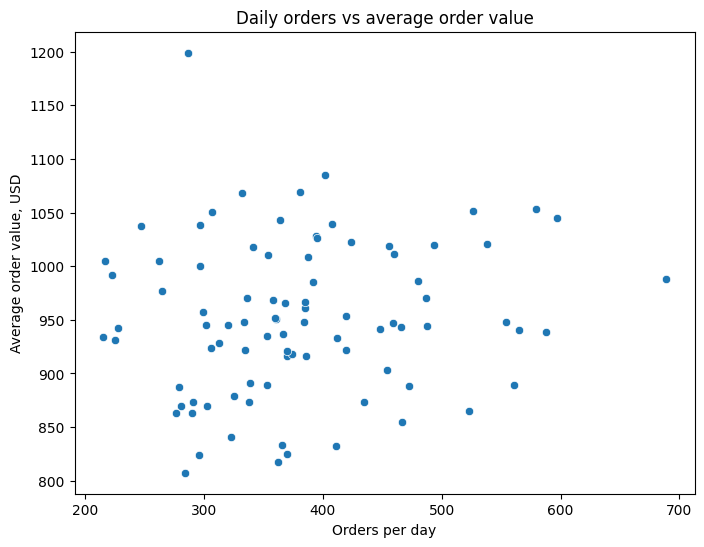

ShapiroResult(statistic=np.float64(0.9630538061543992), pvalue=np.float64(0.013114359372619223))
ShapiroResult(statistic=np.float64(0.978732798049612), pvalue=np.float64(0.15715561941056888))
SignificanceResult(statistic=np.float64(0.15462310682364203), pvalue=np.float64(0.1503148645889366))


In [14]:
# Number of orders vs average order value per day
orders_per_day = df_clean.groupby('session_date')['product_price'].count()
aov_per_day = df_clean.groupby('session_date')['product_price'].mean()

orders_aov = pd.DataFrame({
    'orders': orders_per_day,
    'avg_order_value': aov_per_day
}).reset_index()

# Days without orders
orders_aov = orders_aov.dropna(subset=['avg_order_value'])
print('Days in analysis:', len(orders_aov))

plt.figure(figsize=(8, 6))
sns.scatterplot(data=orders_aov, x='orders', y='avg_order_value')
plt.title('Daily orders vs average order value')
plt.xlabel('Orders per day')
plt.ylabel('Average order value, USD')
plt.show()

print(stats.shapiro(orders_aov['orders']))
print(stats.shapiro(orders_aov['avg_order_value']))
print(stats.spearmanr(orders_aov['orders'], orders_aov['avg_order_value']))

**Daily orders vs average order value**

January 28 to 31 were excluded because of incomplete data, as in the rest of the per-day analysis, leaving 88 days. Orders per day are not normally distributed (p = 0.013), while average order value is (p = 0.157), so Spearman is used. The coefficient is 0.15 with p = 0.15, so the link is weak and not statistically significant. Busier days bring more orders, but customers do not buy more expensive items on those days, so revenue growth comes from order volume rather than from basket size.

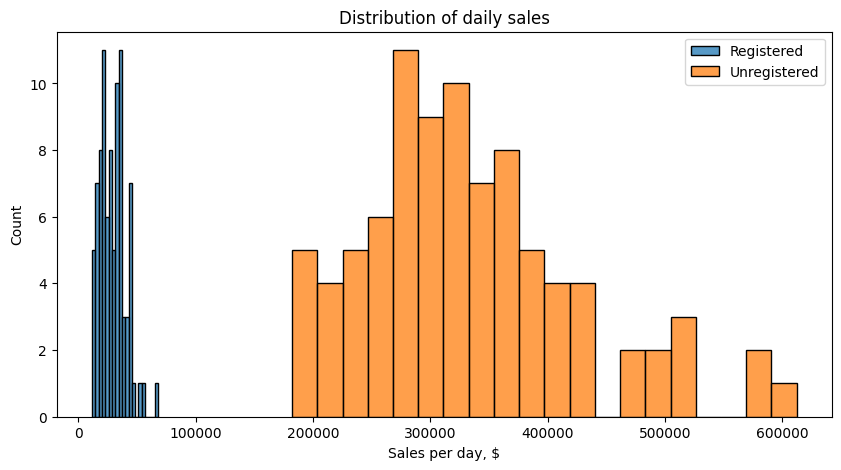

Registered: ShapiroResult(statistic=np.float64(0.9591810175035426), pvalue=np.float64(0.007295139880540744))
Unregistered: ShapiroResult(statistic=np.float64(0.9521579282190968), pvalue=np.float64(0.0026183359245325936))
Mean daily sales: registered 29347 | unregistered 333968
MannwhitneyuResult(statistic=np.float64(0.0), pvalue=np.float64(2.2159276950123465e-30))


In [15]:
#Daily sales: registered vs unregistered users
registered = df_clean.dropna(subset=['account_id'])
unregistered = df_clean[df_clean['account_id'].isna()]

reg_daily = registered.groupby('session_date')['product_price'].sum().reset_index()
reg_daily = reg_daily.rename(columns={'product_price': 'registered_sales'})

unreg_daily = unregistered.groupby('session_date')['product_price'].sum().reset_index()
unreg_daily = unreg_daily.rename(columns={'product_price': 'unregistered_sales'})

reg_compare = pd.merge(reg_daily, unreg_daily, on='session_date')
reg_compare.head()

plt.figure(figsize=(10, 5))
sns.histplot(reg_compare['registered_sales'], bins=20, label='Registered')
sns.histplot(reg_compare['unregistered_sales'], bins=20, label='Unregistered')
plt.title('Distribution of daily sales')
plt.xlabel('Sales per day, $')
plt.legend()
plt.show()

print('Registered:', stats.shapiro(reg_compare['registered_sales']))
print('Unregistered:', stats.shapiro(reg_compare['unregistered_sales']))

#Mann-Whitney test
print('Mean daily sales: registered', round(reg_compare['registered_sales'].mean()),
      '| unregistered', round(reg_compare['unregistered_sales'].mean()))
print(stats.mannwhitneyu(reg_compare['registered_sales'], reg_compare['unregistered_sales'],
                         alternative='two-sided'))

**Daily sales of registered vs unregistered users**

January 28 to 31 were excluded because of incomplete data, leaving 88 days. Daily sales are not normally distributed for either group: registered users p = 0.007, unregistered users p = 0.003. Registered and unregistered users are different people, so the samples are independent, not paired. Since both samples deviate from normality, the Mann-Whitney U test is used.

The difference is statistically significant (U = 0, p < 0.001). Unregistered users bring 334K USD per day on average, compared to only 29K USD from registered users, about 11 times more. U = 0 means that the weakest day of unregistered users still beat the best day of registered users. However, this gap comes from the size of the groups rather than from behaviour: registered users account for 8.0% of all sessions and bring 8.1% of revenue, so per session they buy as much as everyone else. Registration does not make users more valuable buyers, and the bulk of revenue comes from guests, so a smooth checkout without registration is critical for the business.

traffic_channel  Direct  Organic Search  Paid Search  Social Search
count              88.0            88.0         88.0           88.0
mean              888.0          1360.0       1031.0          305.0
std               222.0           340.0        257.0           89.0
min               481.0           733.0        578.0          137.0
25%               745.0          1120.0        875.0          238.0
50%               870.0          1332.0       1000.0          310.0
75%              1012.0          1570.0       1184.0          358.0
max              1668.0          2589.0       1959.0          561.0


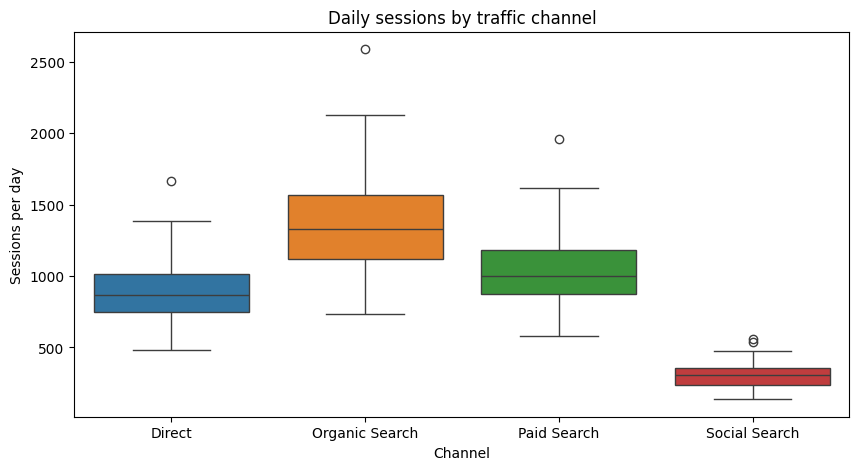

Direct ShapiroResult(statistic=np.float64(0.9711719324100192), pvalue=np.float64(0.04684284582084014))
Organic Search ShapiroResult(statistic=np.float64(0.9667395490509751), pvalue=np.float64(0.02322342693371155))
Paid Search ShapiroResult(statistic=np.float64(0.9645586254902366), pvalue=np.float64(0.016535898889849687))
Social Search ShapiroResult(statistic=np.float64(0.9794998062530369), pvalue=np.float64(0.17740370840264302))
KruskalResult(statistic=np.float64(248.60190039744424), pvalue=np.float64(1.3128407367350972e-53))
Direct vs Organic Search: p = 5.144e-19, significant: True
Direct vs Paid Search: p = 0.0001569, significant: True
Direct vs Social Search: p = 2.908e-30, significant: True
Organic Search vs Paid Search: p = 4.078e-11, significant: True
Organic Search vs Social Search: p = 2.214e-30, significant: True
Paid Search vs Social Search: p = 2.214e-30, significant: True


In [16]:
#Daily sessions by traffic channel
channel_sessions = pd.pivot_table(
    df_known_clean,
    index='session_date',
    columns='traffic_channel',
    values='session_id',
    aggfunc='nunique'
)
channel_sessions = channel_sessions.fillna(0)
print(channel_sessions.describe().round(0))

plt.figure(figsize=(10, 5))
sns.boxplot(data=channel_sessions)
plt.title('Daily sessions by traffic channel')
plt.xlabel('Channel')
plt.ylabel('Sessions per day')
plt.show()

for channel in channel_sessions.columns:
    print(channel, stats.shapiro(channel_sessions[channel]))

#Kruskal-Wallis test
print(stats.kruskal(*[channel_sessions[channel] for channel in channel_sessions.columns]))

#Pairs comparison
channel_pairs = list(itertools.combinations(channel_sessions.columns, 2))
alpha_bonferroni = 0.05 / len(channel_pairs)
for ch_1, ch_2 in channel_pairs:
    p = stats.mannwhitneyu(channel_sessions[ch_1], channel_sessions[ch_2], alternative='two-sided').pvalue
    print(f'{ch_1} vs {ch_2}: p = {p:.4g}, significant: {p < alpha_bonferroni}')

**Daily sessions by traffic channel**

January 28 to 31 were excluded for consistency with the rest of the per-day analysis, and the Undefined channel was not included, leaving 88 days for four channels. Sessions per day are not normally distributed in three of the four channels (Direct p = 0.047, Organic Search p = 0.023, Paid Search p = 0.017), and only Social Search is close to normal (p = 0.177). Since there are more than two independent groups and most of them are not normal, the Kruskal-Wallis test is used.

The differences between channels are statistically significant (H = 248.6, p < 0.001). The pairwise Mann-Whitney comparison with Bonferroni correction (α = 0.05 / 6 = 0.0083) shows that every pair of channels differs significantly, so the channels form a clear ranking. Organic search brings the most traffic with a median of 1,332 sessions per day, followed by paid search (1,000), direct traffic (870) and social search (310). Even the closest pair, direct and paid search, differs significantly (p < 0.001). Since conversion is nearly identical across channels (about 9.6%), this ranking of traffic directly explains the ranking of channels by revenue. Organic search, as the largest and free source of traffic, should remain the main priority for growth.

In [17]:
#Share of organic sessions: Europe vs Americas
regions = df_clean[df_clean['continent'].isin(['Europe', 'Americas'])]

total_sessions = regions.groupby('continent')['session_id'].nunique()
organic_sessions = regions[regions['traffic_channel'] == 'Organic Search'].groupby('continent')['session_id'].nunique()

organic_share = pd.DataFrame({
    'organic_sessions': organic_sessions,
    'total_sessions': total_sessions
})
organic_share['organic_%'] = (organic_share['organic_sessions'] / organic_share['total_sessions'] * 100).round(2)
organic_share

#Z-test
z_stat, p_organic = proportions_ztest(count=organic_share['organic_sessions'], nobs=organic_share['total_sessions'])
print(organic_share)
print(f'z = {z_stat:.3f}, p-value = {p_organic:.4f}')

           organic_sessions  total_sessions  organic_%
continent                                             
Americas              66074          185693      35.58
Europe                22309           62687      35.59
z = -0.025, p-value = 0.9800


**Share of organic traffic: Europe vs Americas**

January 28 to 31 were excluded for consistency with the rest of the per-day analysis. Organic search brings 22,309 of 62,687 sessions in Europe (35.59%) and 66,074 of 185,693 sessions in the Americas (35.58%). Since two proportions are compared, a z-test for two proportions is used. The difference is not statistically significant (z = −0.03, p = 0.98): the share of organic traffic is practically identical in both regions. Organic search plays the same role in Europe and the Americas, bringing about one in three sessions. Search engine optimisation therefore works equally well in both markets, and there is no need for a separate regional strategy for organic traffic.

In [18]:
df.to_csv('portfolio_project_1.csv', index=False)

from google.colab import files
files.download('portfolio_project_1.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tableau: https://public.tableau.com/app/profile/mykhailo.myroshnychenko/viz/E-commerceSalesTrafficDashboard/TrafficUsers